In [1]:
import matplotlib.pyplot as plt
from granad import *

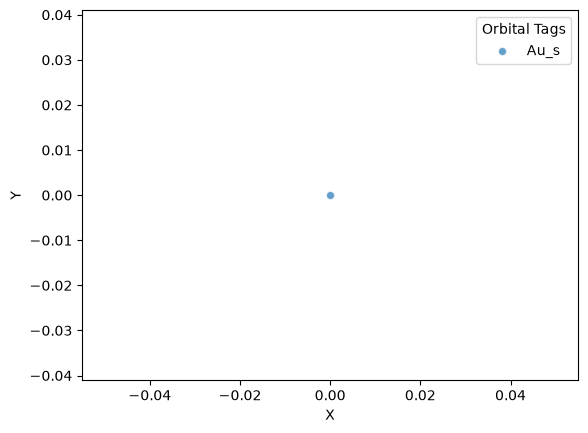

In [2]:
### SETUP GOLDENE PROPERTIES - TWO OPTIONS

# Lattice constant and vectors are the same in both approaches
lattice_constant = 2.62 # Å
lattice_basis = [[1, 0, 0], [-0.5, jnp.sqrt(3)/2, 0]] 

# OPTION 2 - basic goldene definition (no overlap matrix)
# hoppings here taken from DFTB file and inserted manually, 
# you can choose how many you want to include or modify freely
# au_s_hoppings = [-0.21077006, -0.13214205, -0.13783432, -0.14574128, -0.13393609, 
#                  -0.10941234, -0.10042629, -0.07758373, -0.05948577, -0.04918632, -0.03387146, 
#                  -0.02792838, -0.02547764, -0.01914361, -0.01170436, -0.01071128, -0.0087787, 
#                  -0.00603112, -0.00375732, -0.00339428]

au_s_hoppings = [-0.21077006, -0.13214205]   

goldene_simple = (Material("Au")
        .lattice_constant(lattice_constant)  # Approximate lattice constant of hBN
        .lattice_basis(lattice_basis)
        .add_orbital_species("s_gold", atom='Au')
        .add_orbital(position=(0, 0), tag="Au_s", species="s_gold")
        .add_interaction(
            "hamiltonian",
            participants=("s_gold", "s_gold"),
            parameters=au_s_hoppings,  
        )   )

flake = goldene_simple.cut_flake(Rectangle(0.5, 0.5), minimum_neighbor_number = 0)
flake.show_2d()

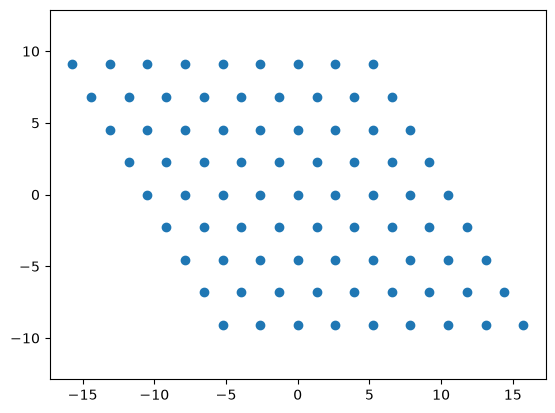

In [3]:
# Define a periodic bulk structure based on the unit cell with one atom

lattice_constant = 2.62
lattice_vectors = lattice_constant*jnp.array([
    [1, 0, 0],
    [-0.5, jnp.sqrt(3)/2, 0] ])
fourier_cutoff = 4

bulk = Periodic(flake, lattice_vectors, fourier_cutoff)
bulk.show_2d(4)

A: [2.39816233 1.38457967 0.        ]
B: [-0.          2.76915933  0.        ]


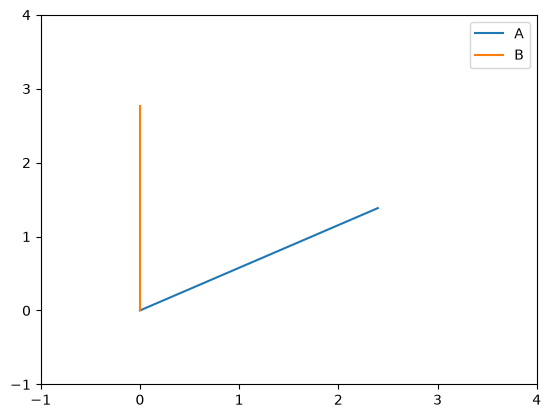

In [4]:
### Calculate reciprocal basis vectors and plot them 

A, B = bulk.reciprocal_basis.T

A_norm = jnp.linalg.norm(A)
B_norm = jnp.linalg.norm(B)
print(f"A: {A}")
print(f"B: {B}")

plt.plot([0, A[0]], [0,A[1]], label="A")
plt.plot([0, B[0]], [0,B[1]], label="B")
ax = plt.gca()
ax.set_xlim([-1, 4])
ax.set_ylim([-1, 4])
plt.legend()
plt.show()

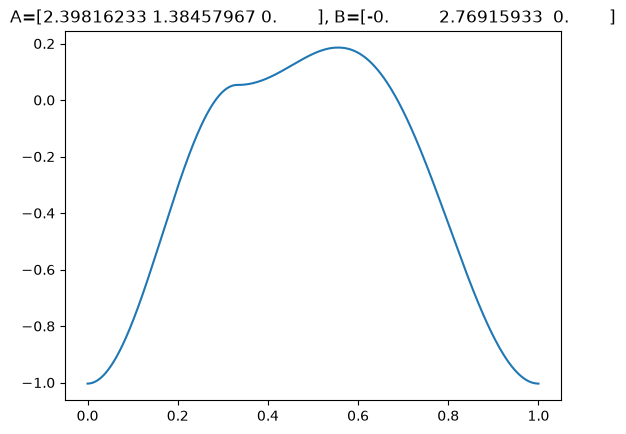

In [5]:
### Plot goldene's band structure along its high-symmetry path in k-space

# Define the path GAMMA -> M -> K -> GAMMA in reciprocal space
ks = jnp.concatenate(
    ( jnp.expand_dims(
          jnp.linspace(0,1/2,150),1)*A,  # Gamma -> M
      jnp.expand_dims(
          jnp.linspace(1/2,1/3,100),1)*A
          + jnp.expand_dims(jnp.linspace(0,1/3,100),1)*B, # M -> K
        jnp.expand_dims(
          jnp.linspace(1/3,0,200),1)*A
          + jnp.expand_dims(jnp.linspace(1/3,0,200),1)*B, # K -> Gamma
    )).T

# Get eigenvalues along the path and plot
energies, eigenvectors = bulk.get_eigenbasis(ks)
plt.plot(jnp.linspace(0, 1, ks.shape[1]), energies)
plt.title(f"A={A}, B={B}")
plt.show()

